Optimization Goal: Maximise

Descriptions of sample application:

Detect likely contamination sources in a two-dimensional area, such as a radiation field, where only proximity yields a non-zero reading. The system uses Bayesian optimisation to tune detection parameters and reliably identify both strong and weak sources.

In [19]:
# IMPORTS AND DEPENDENCIES
# sklearn/SciPy use CPU float64; GPU setup removed because no retained cell uses it.
import warnings
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm
from sklearn.exceptions import ConvergenceWarning
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, RBF
from sklearn.preprocessing import PowerTransformer


In [20]:
# MODEL AND OPTIMISATION HYPERPARAMETERS
# Preserve the R11 local-GP baseline before changing the modelling strategy.
# Signed_Log/RBF/q=0.452591 reproduce the selected transformation/kernel
# without rerunning the removed global-GP cross-validation.
# These are fixed baseline settings, NOT newly cross-validated local choices.
DATA_PATH = "../data/data.csv"  # Change if the notebook and data folder move
FUNCTION_ID = 1
LOCAL_TRANSFORM = "Signed_Log"
LOCAL_KERNEL = "RBF"
LOCAL_SCALE_QUANTILE = 0.452591  # Rounded from R11 global selection; use full q if available
LOCAL_TRAIN_RADIUS = 0.04
LOCAL_SEARCH_RADIUS = 0.02  # Baseline replication; shrink only AFTER comparing outputs
LOCAL_GP_ALPHA = 1e-8
LOCAL_GP_RESTARTS = 20
LOCAL_LENGTH_SCALE_BOUNDS = (1e-3, 8e-2)
LOCAL_CONSTANT_BOUNDS = (1e-3, 1e3)
LOCAL_GP_NORMALIZE_Y = True
LOCAL_GP_RANDOM_SEED = 42
ACQUISITION_GRID_RESOLUTION = 250
EI_XI = 0.01
UCB_KAPPA = 1.96
PREDICTION_INTERVAL_Z = 1.96
BOUNDARY_FRACTION = 0.02
DIRECTIONAL_POINTS = 300
DIRECTIONAL_INTERVAL_Z = 1.96
STABILITY_TRAIN_RADII = [0.03, 0.04, 0.05, 0.06]
STABILITY_GRID_RESOLUTION = 150
ROBUSTNESS_GRID_RESOLUTION = 400
PI_TOP_FRACTIONS = [0.01, 0.05]
TRAJECTORY_ROUNDS = [6, 7, 9, 10, 11]  # Add future rounds only when they follow the local trajectory
TRAJECTORY_GRID_POINTS = 1001
TRAJECTORY_T_MIN, TRAJECTORY_T_MAX = 0.0, 2.0
EXTENDED_T_MIN, EXTENDED_T_MAX, EXTENDED_GRID_POINTS = 0.0, 5.0, 5001
QUADRATIC_BOOTSTRAP_SAMPLES = 10000
QUADRATIC_RELATIVE_NOISE = 0.01  # Hypothetical perturbation; not measurement noise
QUADRATIC_RANDOM_SEED = 42
VERTEX_T_MAX = 5.0
# Optional experimental radius sensitivity; does not alter baseline GP/acquisition.
EXPLORATION_RADII = [0.0005, 0.001, 0.002, 0.005]


In [21]:
# =============================================================================
# DATA LOADING
# =============================================================================
# Loads the centrally prepared BBO dataset and selects the active function.
# Active input dimensions are inferred from the x-columns that contain data.

# round_trip parsing keeps float64 values exactly as written in the CSV
data = pd.read_csv(DATA_PATH, float_precision="round_trip")
function_data = data[data["function"] == FUNCTION_ID].copy()

feature_cols = [
    f"x{i}" for i in range(1, 9)
    if function_data[f"x{i}"].notna().any()
]

# Modelling arrays
X = function_data[feature_cols].to_numpy()
y = function_data["y"].to_numpy()

# Display dataframe
df = function_data[[*feature_cols, "y", "round"]].copy()
df["Stage"] = df["round"].apply(
    lambda r: "Initial Data" if r == 0 else f"Week {r}"
)
df = df.rename(columns={"round": "Round"})
df = df[[*feature_cols, "y", "Stage", "Round"]]

# Display formatting only — underlying float64 values are unchanged
pd.set_option(
    "display.float_format",
    lambda v: f"{v:.6e}" if abs(v) < 1e-3 and v != 0 else f"{v:.6f}"
)

print(f"Function {FUNCTION_ID} observations: {len(df)}")
print(f"Active features: {feature_cols}")
print(f"Dimensions: {len(feature_cols)}")
print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")
print(f"Rounds: R0–R{df['Round'].max()}")

display(df)

Function 1 observations: 21
Active features: ['x1', 'x2']
Dimensions: 2
X shape: (21, 2)
y shape: (21,)
Rounds: R0–R11


,x1,x2,y,Stage,Round
0,0.319404,0.762959,1.322677e-79,Initial Data,0
1,0.574329,0.879898,1.033078e-46,Initial Data,0
2,0.731024,0.733000,7.710875e-16,Initial Data,0
3,0.840353,0.264732,3.341771e-124,Initial Data,0
4,0.650114,0.681526,-0.003606,Initial Data,0
5,0.410437,0.147554,-2.159249e-54,Initial Data,0
6,0.312691,0.078723,-2.089093e-91,Initial Data,0
7,0.683418,0.861057,2.535001e-40,Initial Data,0
8,0.082507,0.403488,3.606771e-81,Initial Data,0
9,0.883890,0.582254,6.229856e-48,Initial Data,0


In [22]:
# TARGET TRANSFORMATION DIAGNOSTICS
# Compare monotonic target transformations before selecting a GP or kernel.
# All transformations preserve the ordering of y and therefore the original
# maximisation objective.
#
# This cell remains CPU/float64 because the dataset is very small and the
# transformations benefit from full numerical precision.

y_raw = y

positive = y_raw > 0
negative = y_raw < 0
zero = y_raw == 0
nonzero_abs = np.abs(y_raw[y_raw != 0])

print("RAW TARGET DIAGNOSTIC")
print("-" * 80)
print(f"Observations: {len(y_raw)}")
print(f"Positive:     {positive.sum()}")
print(f"Negative:     {negative.sum()}")
print(f"Zero:         {zero.sum()}")
print(f"Minimum y:    {np.min(y_raw):.16e}")
print(f"Maximum y:    {np.max(y_raw):.16e}")
print(f"Smallest |y|: {np.min(nonzero_abs):.16e}")
print(f"Largest |y|:  {np.max(nonzero_abs):.16e}")
print(f"|y| range:    {np.ptp(np.log10(nonzero_abs)):.2f} orders of magnitude")

# -------------------------------------------------------------------------
# Build target transformations
# -------------------------------------------------------------------------
target_transforms = pd.DataFrame(index=df.index)
target_transforms["Raw"] = y_raw

pt = PowerTransformer(method="yeo-johnson", standardize=False)

target_transforms["Yeo_Johnson"] = (
    pt.fit_transform(y_raw.reshape(-1, 1)).ravel()
)

# -------------------------------------------------------------------------
# Data-derived transformation scales
# -------------------------------------------------------------------------
scale_candidates = {
    "Q25": np.quantile(nonzero_abs, 0.25),
    "Median": np.quantile(nonzero_abs, 0.50),
    "Q75": np.quantile(nonzero_abs, 0.75),
}

for scale_name, scale in scale_candidates.items():

    target_transforms[f"Asinh_{scale_name}"] = np.arcsinh(
        y_raw / scale
    )

    target_transforms[f"Signed_Log_{scale_name}"] = (
        np.sign(y_raw)
        * np.log1p(np.abs(y_raw) / scale)
    )

# -------------------------------------------------------------------------
# Transformation summary
# -------------------------------------------------------------------------
summary = target_transforms.agg(
    ["min", "max", "mean", "std"]
).T

summary["Range"] = summary["max"] - summary["min"]

print("\nDATA-DERIVED SCALE PARAMETERS")

for name, scale in scale_candidates.items():
    print(f"{name:<8}: {scale:.16e}")

print(f"\nYeo-Johnson lambda: {pt.lambdas_[0]:.6f}")

print("\nTRANSFORMATION SUMMARY")
display(summary)

# -------------------------------------------------------------------------
# Observation-level comparison
# -------------------------------------------------------------------------
transform_display = df[
    ["Round", *feature_cols, "y"]
].copy()

for column in target_transforms.columns:
    transform_display[column] = target_transforms[column]

print("\nOBSERVATION-LEVEL TRANSFORMATIONS")
display(transform_display)

RAW TARGET DIAGNOSTIC
--------------------------------------------------------------------------------
Observations: 21
Positive:     14
Negative:     7
Zero:         0
Minimum y:    -1.5093235658832641e-02
Maximum y:    3.5455529902955166e-06
Smallest |y|: 3.3417710076760228e-124
Largest |y|:  1.5093235658832641e-02
|y| range:    121.65 orders of magnitude

DATA-DERIVED SCALE PARAMETERS
Q25     : 2.1592490357331095e-54
Median  : 1.5361704975146545e-17
Q75     : 3.2591747859009212e-06

Yeo-Johnson lambda: 1087.870985

TRANSFORMATION SUMMARY


,min,max,mean,std,Range
Raw,-0.015093,3.545553e-06,-8.896414e-04,0.003348,0.015097
Yeo_Johnson,-9.209196e-04,3.552393e-06,-8.602379e-05,2.745127e-04,9.244720e-04
Asinh_Q25,-120.069473,111.713165,28.346349,75.299104,231.782638
Signed_Log_Q25,-119.376326,111.020018,28.124038,74.808910,230.396344
Asinh_Median,-35.214293,26.857985,5.271499,17.747587,62.072277
Signed_Log_Median,-34.521145,26.164838,5.083354,17.319245,60.685983
Asinh_Q75,-9.133675,0.942162,-0.586197,2.641907,10.075837
Signed_Log_Q75,-8.440744,0.736144,-0.566405,2.409859,9.176887



OBSERVATION-LEVEL TRANSFORMATIONS


,Round,x1,x2,y,Raw,Yeo_Johnson,Asinh_Q25,Signed_Log_Q25,Asinh_Median,Signed_Log_Median,Asinh_Q75,Signed_Log_Q75
0,0,0.319404,0.762959,1.322677e-79,1.322677e-79,1.322677e-79,6.125635e-26,6.125635e-26,8.610223e-63,8.610223e-63,4.058319e-74,4.058319e-74
1,0,0.574329,0.879898,1.033078e-46,1.033078e-46,1.033078e-46,18.376610,17.683463,6.725023e-30,6.725023e-30,3.169754e-41,3.169754e-41
2,0,0.731024,0.733000,7.710875e-16,7.710875e-16,7.710875e-16,89.464252,88.771105,4.609171,3.935650,2.365898e-10,2.365898e-10
3,0,0.840353,0.264732,3.341771e-124,3.341771e-124,3.341771e-124,1.547654e-70,1.547654e-70,2.175391e-107,2.175391e-107,1.025343e-118,1.025343e-118
4,0,0.650114,0.681526,-0.003606,-0.003606,-9.024396e-04,-118.637843,-117.944696,-33.782662,-33.089515,-7.702045,-7.009801
5,0,0.410437,0.147554,-2.159249e-54,-2.159249e-54,-2.159249e-54,-0.881374,-0.693147,-1.405605e-37,-1.405605e-37,-6.625140e-49,-6.625140e-49
6,0,0.312691,0.078723,-2.089093e-91,-2.089093e-91,-2.089093e-91,-9.675092e-38,-9.675092e-38,-1.359936e-74,-1.359936e-74,-6.409884e-86,-6.409884e-86
7,0,0.683418,0.861057,2.535001e-40,2.535001e-40,2.535001e-40,33.089772,32.396625,1.650208e-23,1.650208e-23,7.778046e-35,7.778046e-35
8,0,0.082507,0.403488,3.606771e-81,3.606771e-81,3.606771e-81,1.670382e-27,1.670382e-27,2.347898e-64,2.347898e-64,1.106652e-75,1.106652e-75
9,0,0.883890,0.582254,6.229856e-48,6.229856e-48,6.229856e-48,15.568251,14.875104,4.055446e-31,4.055446e-31,1.911483e-42,1.911483e-42


In [23]:
# GLOBAL GP AND GLOBAL MODEL SELECTION REMOVED
# The full-domain response spans more than 120 orders of magnitude and is
# strongly non-stationary. Global GP ARD length scales were poorly identified
# (x1 effectively flat), and full-domain LOOCV did not justify using the
# global model to select local candidates. The former global transformation ×
# kernel search, residual diagnostic, and final global fit are omitted.
# To reproduce the R11 local baseline, the previously selected Signed_Log,
# RBF and scale quantile are frozen in the configuration cell above.
# This is a baseline reproduction, not a new independent local model selection.


In [24]:
# LOCAL TARGET TRANSFORMATION
# Signed-log is monotone and preserves the maximisation ordering.
# The scale is estimated from the current dataset at the frozen R11 quantile.
# Refitting this scale when adding observations is intentional; this may change
# GP hyperparameters, but does not leak a held-out label in a predictive CV test.
y_original = y
X_model = X
n_features = X.shape[1]
selected_transform, selected_kernel = LOCAL_TRANSFORM, LOCAL_KERNEL
selected_q = LOCAL_SCALE_QUANTILE
selected_transformer = None
selected_scale = float(np.quantile(np.abs(y_original[y_original != 0]), selected_q))

def transform_target(values, kind, scale=None, transformer=None):
    v = np.asarray(values, dtype=np.float64)
    if kind == "Raw": return v
    if kind == "Yeo_Johnson": return transformer.transform(v.reshape(-1, 1)).ravel()
    if kind == "Asinh": return np.arcsinh(v / scale)
    if kind == "Signed_Log": return np.sign(v) * np.log1p(np.abs(v) / scale)
    raise ValueError(f"Unsupported transform: {kind}")

def inverse_transform_target(values, kind, scale=None, transformer=None):
    v = np.asarray(values, dtype=np.float64)
    if kind == "Raw": return v
    if kind == "Yeo_Johnson": return transformer.inverse_transform(v.reshape(-1, 1)).ravel()
    if kind == "Asinh": return scale * np.sinh(v)
    if kind == "Signed_Log": return np.sign(v) * scale * np.expm1(np.abs(v))
    raise ValueError(f"Unsupported transform: {kind}")

print(f"Local transform: {selected_transform} | kernel: {selected_kernel} | scale={selected_scale:.16e}")

# Backwards-compatible name used in the retained acquisition cells.
inverse_target = inverse_transform_target


Local transform: Signed_Log | kernel: RBF | scale=7.9604355181211067e-19


In [25]:
# LOCAL TRUST REGION
# Define a bounded local exploitation region around the current incumbent.
#
# IMPORTANT:
# The local training neighbourhood and local search region are controlled by
# explicit hyperparameters shown immediately below.
#
# These are NOT derived from the global GP ARD length scales.

# HYPERPARAMETERS — LOCAL MODEL / TRUST REGION

# CURRENT INCUMBENT

incumbent_idx = np.argmax(y_original)

incumbent_x = X_model[
    incumbent_idx
].copy()

incumbent_y = y_original[
    incumbent_idx
]

# TRAINING NEIGHBOURHOOD

train_radii = np.full(
    n_features,
    LOCAL_TRAIN_RADIUS,
    dtype=np.float64
)

train_lower_bounds = np.maximum(
    incumbent_x - train_radii,
    0.0
)

train_upper_bounds = np.minimum(
    incumbent_x + train_radii,
    1.0
)

# Normalised Euclidean distance from incumbent
train_distances = np.sqrt(
    np.sum(
        (
            (X_model - incumbent_x)
            / train_radii
        ) ** 2,
        axis=1
    )
)

local_train_mask = train_distances <= 1.0

# LOCAL SEARCH REGION

search_radii = np.full(
    n_features,
    LOCAL_SEARCH_RADIUS,
    dtype=np.float64
)

lower_bounds = np.maximum(
    incumbent_x - search_radii,
    0.0
)

upper_bounds = np.minimum(
    incumbent_x + search_radii,
    1.0
)

# OUTPUT

print(
    f"FUNCTION {FUNCTION_ID}: LOCAL TRUST REGION"
)

print("-" * 80)

print(
    f"Incumbent y: {incumbent_y:.16e}"
)

print(
    f"Incumbent x: {incumbent_x}"
)

print(
    f"\nLOCAL_TRAIN_RADIUS:  "
    f"{LOCAL_TRAIN_RADIUS:.6f}"
)

print(
    f"LOCAL_SEARCH_RADIUS: "
    f"{LOCAL_SEARCH_RADIUS:.6f}"
)

print(
    f"\nObservations in local training neighbourhood: "
    f"{local_train_mask.sum()}"
)

# TRAINING BOUNDS

print("\nLOCAL TRAINING BOUNDS")

for (
    feature,
    centre,
    radius,
    lower,
    upper
) in zip(
    feature_cols,
    incumbent_x,
    train_radii,
    train_lower_bounds,
    train_upper_bounds
):

    print(
        f"{feature}: "
        f"centre={centre:.6f}, "
        f"radius={radius:.6f}, "
        f"bounds=[{lower:.6f}, {upper:.6f}]"
    )

# SEARCH BOUNDS

print("\nLOCAL SEARCH BOUNDS")

for (
    feature,
    centre,
    radius,
    lower,
    upper
) in zip(
    feature_cols,
    incumbent_x,
    search_radii,
    lower_bounds,
    upper_bounds
):

    print(
        f"{feature}: "
        f"centre={centre:.6f}, "
        f"radius={radius:.6f}, "
        f"bounds=[{lower:.6f}, {upper:.6f}]"
    )

# OBSERVATIONS USED BY LOCAL MODEL

local_observations = df.loc[
    local_train_mask,
    [
        *feature_cols,
        "y",
        "Stage",
        "Round"
    ]
].copy()

local_observations[
    "Local_Train_Distance"
] = train_distances[
    local_train_mask
]

print(
    "\nOBSERVATIONS IN LOCAL TRAINING NEIGHBOURHOOD"
)

display(
    local_observations.sort_values(
        "Local_Train_Distance"
    )
)

FUNCTION 1: LOCAL TRUST REGION
--------------------------------------------------------------------------------
Incumbent y: 3.5455529902955166e-06
Incumbent x: [0.67155 0.70077]

LOCAL_TRAIN_RADIUS:  0.040000
LOCAL_SEARCH_RADIUS: 0.020000

Observations in local training neighbourhood: 8

LOCAL TRAINING BOUNDS
x1: centre=0.671550, radius=0.040000, bounds=[0.631550, 0.711550]
x2: centre=0.700770, radius=0.040000, bounds=[0.660770, 0.740770]

LOCAL SEARCH BOUNDS
x1: centre=0.671550, radius=0.020000, bounds=[0.651550, 0.691550]
x2: centre=0.700770, radius=0.020000, bounds=[0.680770, 0.720770]

OBSERVATIONS IN LOCAL TRAINING NEIGHBOURHOOD


,x1,x2,y,Stage,Round,Local_Train_Distance
255,0.671550,0.700770,3.545553e-06,Week 11,11,0.000000
247,0.671200,0.700600,3.502779e-06,Week 10,10,0.009728
239,0.670800,0.700400,3.410778e-06,Week 9,9,0.020908
223,0.670400,0.700200,3.259175e-06,Week 7,7,0.032088
215,0.670000,0.700000,3.037630e-06,Week 6,6,0.043268
207,0.693467,0.708543,7.172332e-08,Week 5,5,0.581364
4,0.650114,0.681526,-0.003606,Initial Data,0,0.720164
199,0.703200,0.715500,1.388951e-09,Week 4,4,0.872745


In [26]:
# LOCAL GP FIT
# Fit a separate Gaussian Process to observations in the local training
# neighbourhood.
#
# Only the local GP is fitted; the global GP has been removed.
#
# The local model:
#   - uses only observations selected by local_train_mask
#   - uses explicitly configured target transformation and kernel family
#   - learns new kernel parameters from the local observations
#

# HYPERPARAMETERS — LOCAL GP
# These values are tunable modelling choices.
# They will later be moved to the central notebook hyperparameter cell.

# LOCAL TRAINING DATA

X_local = X_model[
    local_train_mask
].copy()

y_local_original = y_original[
    local_train_mask
].copy()

n_local = len(y_local_original)

if n_local < 2:
    raise ValueError(
        "At least two local observations are required to fit the local GP."
    )

# APPLY THE GLOBALLY SELECTED TARGET TRANSFORMATION
# Do NOT re-estimate transformation parameters from only four local points.
#
# If the selected transformation requires a scale or fitted transformer,
# reuse the values already obtained during the global model fit.

y_local_transformed = transform_target(
    y_local_original,
    selected_transform,
    scale=selected_scale,
    transformer=selected_transformer
)

# LOCAL KERNEL
# Reuse the configured kernel FAMILY, but fit new local kernel
# hyperparameters.
#
# ARD remains active: each input dimension receives its own local
# length scale.

initial_local_length_scales = np.full(
    n_features,
    LOCAL_SEARCH_RADIUS,
    dtype=np.float64
)

local_constant = ConstantKernel(
    constant_value=1.0,
    constant_value_bounds=LOCAL_CONSTANT_BOUNDS
)

if selected_kernel == "RBF":

    local_base_kernel = RBF(
        length_scale=initial_local_length_scales,
        length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS
    )

elif selected_kernel == "Matern_3_2":

    local_base_kernel = Matern(
        length_scale=initial_local_length_scales,
        length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS,
        nu=1.5
    )

elif selected_kernel == "Matern_5_2":

    local_base_kernel = Matern(
        length_scale=initial_local_length_scales,
        length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS,
        nu=2.5
    )

else:

    raise ValueError(
        f"Unsupported selected kernel: {selected_kernel}"
    )

local_kernel = (
    local_constant
    * local_base_kernel
)

# FIT LOCAL GP

gp_local = GaussianProcessRegressor(
    kernel=local_kernel,
    alpha=LOCAL_GP_ALPHA,
    normalize_y=LOCAL_GP_NORMALIZE_Y,
    n_restarts_optimizer=LOCAL_GP_RESTARTS,
    random_state=LOCAL_GP_RANDOM_SEED
)

with warnings.catch_warnings(record=True) as local_fit_warnings:

    warnings.simplefilter("always")

    gp_local.fit(
        X_local,
        y_local_transformed
    )

# EXTRACT LOCAL ARD LENGTH SCALES

local_length_scales = np.asarray(
    gp_local.kernel_.k2.length_scale,
    dtype=np.float64
)

if local_length_scales.ndim == 0:

    local_length_scales = np.repeat(
        local_length_scales,
        n_features
    )

# OUTPUT

print(
    f"FUNCTION {FUNCTION_ID}: LOCAL GP FIT"
)

print("-" * 80)

print(
    f"Local observations: "
    f"{n_local}"
)

print(
    f"Transformation: "
    f"{selected_transform}"
)

print(
    f"Kernel family: "
    f"{selected_kernel}"
)

print(
    f"Log-marginal likelihood: "
    f"{gp_local.log_marginal_likelihood_value_:.6f}"
)

print(
    f"Fit warnings: "
    f"{len(local_fit_warnings)}"
)

print(
    "\nFITTED LOCAL KERNEL"
)

print(
    gp_local.kernel_
)

print(
    "\nLOCAL ARD LENGTH SCALES"
)

for feature, length_scale in zip(
    feature_cols,
    local_length_scales
):

    print(
        f"{feature}: "
        f"{length_scale:.6f}"
    )

FUNCTION 1: LOCAL GP FIT
--------------------------------------------------------------------------------
Local observations: 8
Transformation: Signed_Log
Kernel family: RBF
Log-marginal likelihood: 17.758757
Fit warnings: 2

FITTED LOCAL KERNEL
1.51**2 * RBF(length_scale=[0.0774, 0.0116])

LOCAL ARD LENGTH SCALES
x1: 0.077352
x2: 0.011602


In [27]:
# LOCAL ACQUISITION FUNCTION COMPARISON
# Compare Posterior Mean, Expected Improvement (EI), Probability of Improvement
# (PI), and Upper Confidence Bound (UCB) inside the LOCAL search region.
#
# IMPORTANT:
# Only gp_local is used; the global GP was removed.

# HYPERPARAMETERS — LOCAL ACQUISITION
# These are tunable optimisation choices.
# They will later be moved to the central notebook hyperparameter cell.

BOUNDARY_TOLERANCE = 1e-8

# BUILD LOCAL CANDIDATE GRID

# Current implementation is for the 2-D Function 1 surface.
# We will generalise this later if required for higher-dimensional functions.

if n_features != 2:
    raise ValueError(
        "This acquisition-grid cell currently supports 2-D functions only."
    )

g1, g2 = np.meshgrid(
    np.linspace(
        lower_bounds[0],
        upper_bounds[0],
        ACQUISITION_GRID_RESOLUTION
    ),
    np.linspace(
        lower_bounds[1],
        upper_bounds[1],
        ACQUISITION_GRID_RESOLUTION
    )
)

X_candidates = np.column_stack([
    g1.ravel(),
    g2.ravel()
])

# LOCAL GP PREDICTIONS

mu, sigma = gp_local.predict(
    X_candidates,
    return_std=True
)

# CURRENT INCUMBENT ON TRANSFORMED SCALE

incumbent_transformed = transform_target(
    np.array(
        [incumbent_y],
        dtype=np.float64
    ),
    selected_transform,
    scale=selected_scale,
    transformer=selected_transformer
)[0]

# EXPECTED IMPROVEMENT

improvement = (
    mu
    - incumbent_transformed
    - EI_XI
)

z = np.divide(
    improvement,
    sigma,
    out=np.zeros_like(improvement),
    where=sigma > 0
)

ei = (
    improvement * norm.cdf(z)
    + sigma * norm.pdf(z)
)

ei[sigma == 0] = 0.0

# PROBABILITY OF IMPROVEMENT

pi = norm.cdf(z)

pi[sigma == 0] = (
    improvement[sigma == 0] > 0
).astype(float)

# UPPER CONFIDENCE BOUND

ucb = (
    mu
    + UCB_KAPPA * sigma
)

# WINNER INDICES

winner_indices = {
    "Posterior Mean": np.argmax(mu),
    "EI": np.argmax(ei),
    "PI": np.argmax(pi),
    "UCB": np.argmax(ucb)
}

# BUILD COMPARISON TABLE

records = []

for method, idx in winner_indices.items():

    candidate_x = X_candidates[
        idx
    ]

    pred_y = inverse_target(
        np.array(
            [mu[idx]],
            dtype=np.float64
        ),
        selected_transform,
        scale=selected_scale,
        transformer=selected_transformer
    )[0]

    # -------------------------------------------------------------
    # Boundary diagnostic
    # -------------------------------------------------------------

    on_lower_boundary = np.isclose(
        candidate_x,
        lower_bounds,
        atol=BOUNDARY_TOLERANCE,
        rtol=0.0
    )

    on_upper_boundary = np.isclose(
        candidate_x,
        upper_bounds,
        atol=BOUNDARY_TOLERANCE,
        rtol=0.0
    )

    boundary_features = []

    for feature, lower_hit, upper_hit in zip(
        feature_cols,
        on_lower_boundary,
        on_upper_boundary
    ):

        if lower_hit:
            boundary_features.append(
                f"{feature}:LOW"
            )

        if upper_hit:
            boundary_features.append(
                f"{feature}:HIGH"
            )

    # -------------------------------------------------------------
    # Output record
    # -------------------------------------------------------------

    record = {
        "Method": method
    }

    for feature, value in zip(
        feature_cols,
        candidate_x
    ):

        record[
            feature
        ] = value

    record.update({
        "Pred_Transformed": mu[idx],
        "Pred_y": pred_y,
        "Pred_Std": sigma[idx],
        "EI": ei[idx],
        "PI": pi[idx],
        "UCB": ucb[idx],

        "Distance_to_Incumbent":
            np.linalg.norm(
                candidate_x
                - incumbent_x
            ),

        "On_Search_Boundary":
            len(boundary_features) > 0,

        "Boundary_Features":
            ", ".join(
                boundary_features
            )
            if boundary_features
            else ""
    })

    records.append(
        record
    )

acquisition_summary = pd.DataFrame(
    records
)

# OUTPUT

print(
    f"FUNCTION {FUNCTION_ID}: "
    "LOCAL ACQUISITION COMPARISON"
)

print("-" * 120)

print(
    f"Candidate grid: "
    f"{ACQUISITION_GRID_RESOLUTION} × "
    f"{ACQUISITION_GRID_RESOLUTION} "
    f"= {len(X_candidates):,} points"
)

print(
    f"EI xi: {EI_XI}"
)

print(
    f"UCB kappa: {UCB_KAPPA}"
)

print(
    "\nLOCAL SEARCH BOUNDS"
)

for feature, lower, upper in zip(
    feature_cols,
    lower_bounds,
    upper_bounds
):

    print(
        f"{feature}: "
        f"[{lower:.6f}, {upper:.6f}]"
    )

print(
    "\nACQUISITION WINNERS"
)

display(
    acquisition_summary
)

FUNCTION 1: LOCAL ACQUISITION COMPARISON
------------------------------------------------------------------------------------------------------------------------
Candidate grid: 250 × 250 = 62,500 points
EI xi: 0.01
UCB kappa: 1.96

LOCAL SEARCH BOUNDS
x1: [0.651550, 0.691550]
x2: [0.680770, 0.720770]

ACQUISITION WINNERS


,Method,x1,x2,Pred_Transformed,Pred_y,Pred_Std,EI,PI,UCB,Distance_to_Incumbent,On_Search_Boundary,Boundary_Features
0,Posterior Mean,0.691550,0.699726,36.059658,0.003643,6.227899,7.342233,0.866911,48.266341,0.020027,True,x1:HIGH
1,EI,0.691550,0.699405,36.035559,0.003556,6.469552,7.374745,0.856935,48.715881,0.020047,True,x1:HIGH
2,PI,0.691550,0.701814,34.983385,0.001242,4.662798,6.082332,0.895134,44.122468,0.020027,True,x1:HIGH
3,UCB,0.691550,0.697156,34.189305,5.612593e-04,8.169691,6.391095,0.731939,50.201900,0.020324,True,x1:HIGH


In [28]:
# LOCAL CANDIDATE QUALITY DIAGNOSTIC
# Compare Posterior Mean, EI, PI and UCB candidates produced by the local GP.
#
# Because the GP models a nonlinear transformed target, inverse-transforming
# the GP mean does NOT equal E[y]. Back-transformed values are therefore
# descriptive location indicators only.

# HYPERPARAMETERS — CANDIDATE QUALITY DIAGNOSTIC
# These values are tunable diagnostic choices.
# They will later be moved to the central notebook hyperparameter cell.

# CANDIDATE DIAGNOSTICS

candidate_records = []

region_width = (
    upper_bounds
    - lower_bounds
)

for method, idx in winner_indices.items():

    x_candidate = X_candidates[idx]

    mean_t = mu[idx]

    std_t = sigma[idx]

    # =========================================================================
    # BACK-TRANSFORM POSTERIOR CENTRE AND APPROXIMATE INTERVAL
    # =========================================================================

    back_mean = inverse_target(
        np.array(
            [mean_t],
            dtype=np.float64
        ),
        selected_transform,
        scale=selected_scale,
        transformer=selected_transformer
    )[0]

    back_low = inverse_target(
        np.array(
            [
                mean_t
                - PREDICTION_INTERVAL_Z * std_t
            ],
            dtype=np.float64
        ),
        selected_transform,
        scale=selected_scale,
        transformer=selected_transformer
    )[0]

    back_high = inverse_target(
        np.array(
            [
                mean_t
                + PREDICTION_INTERVAL_Z * std_t
            ],
            dtype=np.float64
        ),
        selected_transform,
        scale=selected_scale,
        transformer=selected_transformer
    )[0]

    # =========================================================================
    # DISTANCE FROM CURRENT INCUMBENT
    # =========================================================================

    raw_distance = np.linalg.norm(
        x_candidate
        - incumbent_x
    )

    # Distance expressed in LOCAL GP length scales
    local_gp_scaled_distance = np.sqrt(
        np.sum(
            (
                (
                    x_candidate
                    - incumbent_x
                )
                / local_length_scales
            ) ** 2
        )
    )

    # =========================================================================
    # DISTANCE TO NEAREST OBSERVED POINT
    # =========================================================================

    observed_distances = np.linalg.norm(
        X_model
        - x_candidate,
        axis=1
    )

    nearest_idx = np.argmin(
        observed_distances
    )

    # =========================================================================
    # SEARCH-REGION BOUNDARY DIAGNOSTIC
    # =========================================================================

    boundary_flags = []

    for (
        feature,
        value,
        low,
        high,
        width
    ) in zip(
        feature_cols,
        x_candidate,
        lower_bounds,
        upper_bounds,
        region_width
    ):

        if (
            value - low
            <= BOUNDARY_FRACTION * width
        ):

            boundary_flags.append(
                f"{feature}=LOW"
            )

        elif (
            high - value
            <= BOUNDARY_FRACTION * width
        ):

            boundary_flags.append(
                f"{feature}=HIGH"
            )

    # =========================================================================
    # OUTPUT RECORD
    # =========================================================================

    record = {
        "Method": method
    }

    for feature, value in zip(
        feature_cols,
        x_candidate
    ):

        record[
            feature
        ] = value

    record.update({

        "BackTransformed_Mean":
            back_mean,

        "BackTransformed_Gain_vs_Inc":
            back_mean
            - incumbent_y,

        "BackTransformed_95_Low":
            back_low,

        "BackTransformed_95_High":
            back_high,

        "Transformed_Mean":
            mean_t,

        "Transformed_Std":
            std_t,

        "EI":
            ei[idx],

        "PI":
            pi[idx],

        "UCB":
            ucb[idx],

        "Distance_to_Inc":
            raw_distance,

        "Local_GP_Scaled_Distance":
            local_gp_scaled_distance,

        "Nearest_Round":
            f"R{int(df.iloc[nearest_idx]['Round'])}",

        "Nearest_y":
            y_original[nearest_idx],

        "Nearest_Distance":
            observed_distances[nearest_idx],

        "Boundary":
            ", ".join(boundary_flags)
            if boundary_flags
            else "Interior"
    })

    candidate_records.append(
        record
    )

candidate_diagnostic = pd.DataFrame(
    candidate_records
)

# FULL DIAGNOSTIC TABLE

print(
    f"FUNCTION {FUNCTION_ID}: "
    "LOCAL CANDIDATE QUALITY DIAGNOSTIC"
)

print("-" * 150)

print(
    f"Prediction interval Z: "
    f"{PREDICTION_INTERVAL_Z}"
)

print(
    f"Boundary fraction: "
    f"{BOUNDARY_FRACTION}"
)

display(
    candidate_diagnostic
)

# DECISION TABLE

decision_table = candidate_diagnostic[
    [
        "Method",
        *feature_cols,
        "BackTransformed_Mean",
        "BackTransformed_Gain_vs_Inc",
        "PI",
        "Transformed_Std",
        "Local_GP_Scaled_Distance",
        "Nearest_Round",
        "Nearest_Distance",
        "Boundary"
    ]
].copy()

print(
    f"\nFUNCTION {FUNCTION_ID}: "
    "CANDIDATE DECISION TABLE"
)

print("-" * 120)

display(
    decision_table
)

FUNCTION 1: LOCAL CANDIDATE QUALITY DIAGNOSTIC
------------------------------------------------------------------------------------------------------------------------------------------------------
Prediction interval Z: 1.96
Boundary fraction: 0.02


,Method,x1,x2,BackTransformed_Mean,BackTransformed_Gain_vs_Inc,BackTransformed_95_Low,BackTransformed_95_High,Transformed_Mean,Transformed_Std,EI,PI,UCB,Distance_to_Inc,Local_GP_Scaled_Distance,Nearest_Round,Nearest_y,Nearest_Distance,Boundary
0,Posterior Mean,0.691550,0.699726,0.003643,0.003639,1.820341e-08,729.024582,36.059658,6.227899,7.342233,0.866911,48.266341,0.020027,0.273775,R5,7.172332e-08,0.009023,x1=HIGH
1,EI,0.691550,0.699405,0.003556,0.003553,1.106591e-08,1142.813097,36.035559,6.469552,7.374745,0.856935,48.715881,0.020047,0.284085,R5,7.172332e-08,0.009337,x1=HIGH
2,PI,0.691550,0.701814,0.001242,0.001238,1.333442e-07,11.563286,34.983385,4.662798,6.082332,0.895134,44.122468,0.020027,0.273775,R5,7.172332e-08,0.006997,x1=HIGH
3,UCB,0.691550,0.697156,5.612593e-04,5.577137e-04,6.237090e-11,5050.624139,34.189305,8.169691,6.391095,0.731939,50.201900,0.020324,0.404855,R5,7.172332e-08,0.011548,x1=HIGH



FUNCTION 1: CANDIDATE DECISION TABLE
------------------------------------------------------------------------------------------------------------------------


,Method,x1,x2,BackTransformed_Mean,BackTransformed_Gain_vs_Inc,PI,Transformed_Std,Local_GP_Scaled_Distance,Nearest_Round,Nearest_Distance,Boundary
0,Posterior Mean,0.691550,0.699726,0.003643,0.003639,0.866911,6.227899,0.273775,R5,0.009023,x1=HIGH
1,EI,0.691550,0.699405,0.003556,0.003553,0.856935,6.469552,0.284085,R5,0.009337,x1=HIGH
2,PI,0.691550,0.701814,0.001242,0.001238,0.895134,4.662798,0.273775,R5,0.006997,x1=HIGH
3,UCB,0.691550,0.697156,5.612593e-04,5.577137e-04,0.731939,8.169691,0.404855,R5,0.011548,x1=HIGH


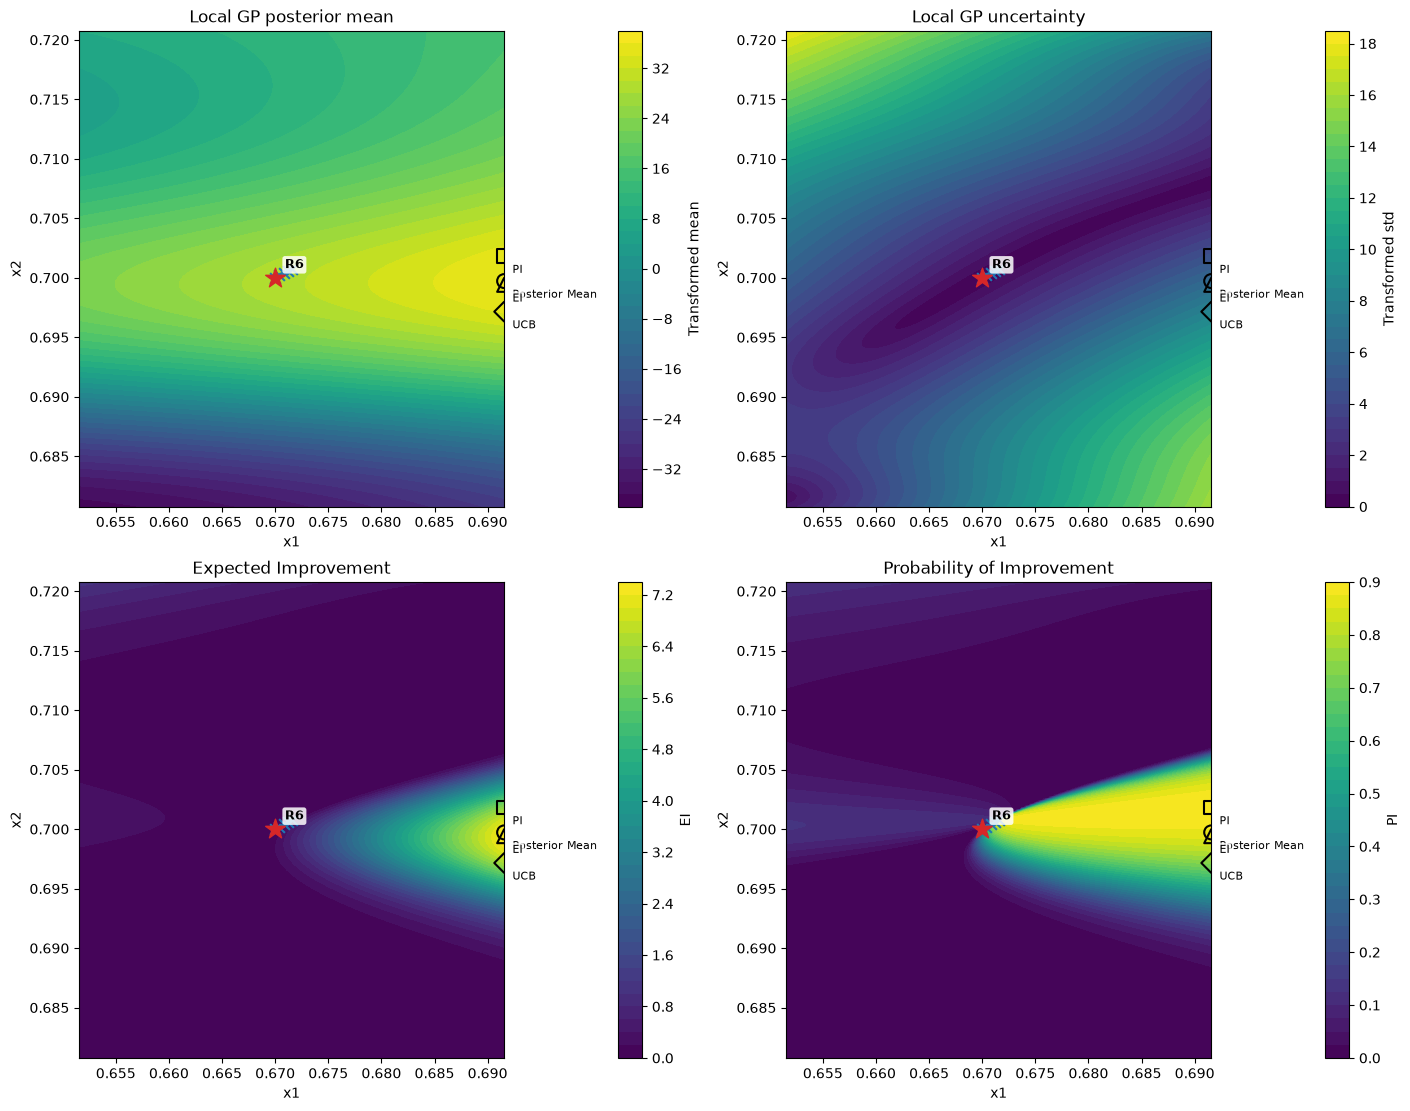

In [29]:
# LOCAL ACQUISITION SURFACES
# Visualise the local GP posterior and acquisition functions inside the local
# search region: transformed posterior mean, posterior uncertainty, Expected
# Improvement and Probability of Improvement.
#
# F1 is two-dimensional, so this visualisation is deliberately 2-D specific.

if n_features != 2:
    raise ValueError("Local acquisition surfaces currently support 2-D functions only.")

grid_res = ACQUISITION_GRID_RESOLUTION

mean_grid = mu.reshape(grid_res, grid_res)
std_grid = sigma.reshape(grid_res, grid_res)
ei_grid = ei.reshape(grid_res, grid_res)
pi_grid = pi.reshape(grid_res, grid_res)

fig, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True)

plot_specs = [
    ("Local GP posterior mean", mean_grid, "Transformed mean"),
    ("Local GP uncertainty", std_grid, "Transformed std"),
    ("Expected Improvement", ei_grid, "EI"),
    ("Probability of Improvement", pi_grid, "PI")
]

candidate_markers = {
    "Posterior Mean": "o",
    "EI": "^",
    "PI": "s",
    "UCB": "D"
}

for ax, (title, surface, cbar_label) in zip(axes.ravel(), plot_specs):
    contour = ax.contourf(g1, g2, surface, levels=40)

    # All observed points
    ax.scatter(
        df[feature_cols[0]],
        df[feature_cols[1]],
        marker="x",
        s=60,
        label="Observed"
    )

    # Highlight recent optimisation rounds
    for round_id in [4, 5, 6]:
        round_rows = df[df["Round"] == round_id]
        if round_rows.empty:
            continue

        row = round_rows.iloc[0]
        ax.scatter(
            row[feature_cols[0]],
            row[feature_cols[1]],
            marker="*",
            s=220
        )
        ax.annotate(
            f"R{round_id}",
            (row[feature_cols[0]], row[feature_cols[1]]),
            xytext=(7, 7),
            textcoords="offset points",
            fontsize=9,
            fontweight="bold",
            bbox=dict(
                boxstyle="round,pad=0.2",
                facecolor="white",
                edgecolor="none",
                alpha=0.85
            )
        )

    # Acquisition winners
    for _, row in acquisition_summary.iterrows():
        ax.scatter(
            row[feature_cols[0]],
            row[feature_cols[1]],
            marker=candidate_markers[row["Method"]],
            s=100,
            facecolors="none",
            edgecolors="black",
            linewidths=1.5
        )
        ax.annotate(
            row["Method"],
            (row[feature_cols[0]], row[feature_cols[1]]),
            xytext=(6, -12),
            textcoords="offset points",
            fontsize=8,
            bbox=dict(
                boxstyle="round,pad=0.15",
                facecolor="white",
                edgecolor="none",
                alpha=0.8
            )
        )

    ax.set_xlim(lower_bounds[0], upper_bounds[0])
    ax.set_ylim(lower_bounds[1], upper_bounds[1])
    ax.set_xlabel(feature_cols[0])
    ax.set_ylabel(feature_cols[1])
    ax.set_title(title)
    fig.colorbar(contour, ax=ax, label=cbar_label)

plt.show()

In [30]:
# SVM SIGN-BOUNDARY DIAGNOSTICS REMOVED
# Sign classification did not distinguish the tiny differences among positive,
# high-performing candidates. Nested LOOCV and the GP/SVM comparison added
# runtime without reliably improving objective-value maximisation.
# The optimisation therefore uses observed y, local GP uncertainty, and
# neighbourhood robustness; the SVM sign classifier is no longer fitted.


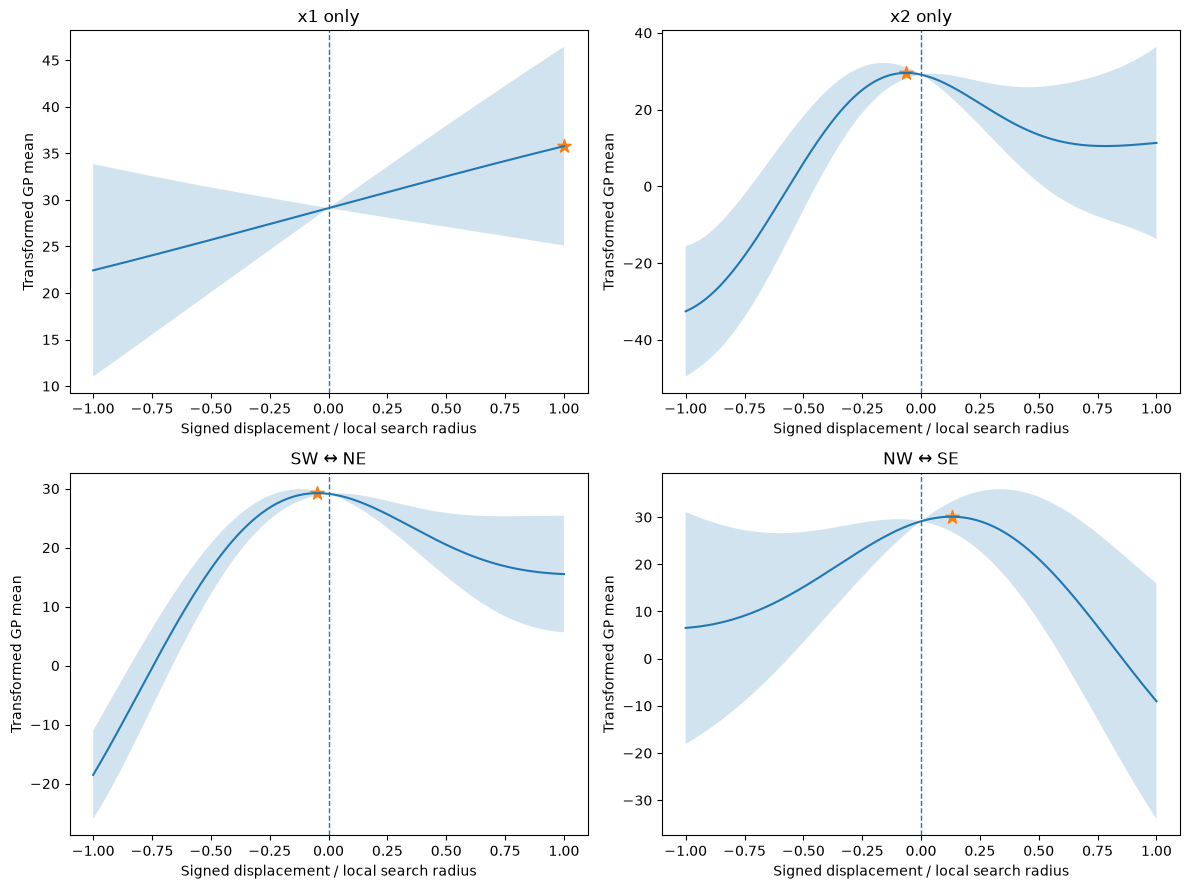

FUNCTION 1: DIRECTIONAL LOCAL GP PROFILES


,Direction,Best_t,x1,x2,Predicted_Transformed_Mean,Predicted_Std
0,x1 only,1.000000,0.691550,0.700770,35.770619,5.444712
1,x2 only,-0.063545,0.671550,0.699499,29.570479,0.744959
2,SW ↔ NE,-0.050167,0.670841,0.700061,29.239264,0.208334
3,NW ↔ SE,0.130435,0.673395,0.698925,30.091971,1.636471



LOCAL MODEL STABILITY


,Train_Radius,N_Local,x1_LengthScale,x2_LengthScale,PI_x1,PI_x2,PI_Max,PI_Distance_From_Incumbent
0,0.030000,7,0.080000,0.011536,0.673832,0.700904,0.764656,0.002286
1,0.040000,8,0.077355,0.011602,0.691550,0.701710,0.895538,0.020022
2,0.050000,8,0.077355,0.011602,0.691550,0.701710,0.895538,0.020022
3,0.060000,8,0.077355,0.011602,0.691550,0.701710,0.895538,0.020022



LOCAL GP LEAVE-ONE-OUT


,Original_Index,x1,x2,Actual_y,Actual_Transformed,Predicted_Transformed,Predicted_Std,Standardised_Residual,Actual_Sign,Predicted_Sign
0,4,0.650114,0.681526,-0.003606,-36.049494,27.371748,3.385520,-18.733085,-1,1
1,13,0.703200,0.715500,1.388951e-09,21.279916,26.770025,8.617224,-0.637109,1,1
2,14,0.693467,0.708543,7.172332e-08,25.224183,22.742693,2.107435,1.177493,1,1
3,15,0.670000,0.700000,3.037630e-06,28.970200,28.980368,0.006507,-1.562686,1,1
4,16,0.670400,0.700200,3.259175e-06,29.040597,29.037756,0.001940,1.463930,1,1
5,18,0.670800,0.700400,3.410778e-06,29.086063,29.086411,0.002236,-0.155592,1,1
6,19,0.671200,0.700600,3.502779e-06,29.112679,29.114336,0.002074,-0.798963,1,1
7,20,0.671550,0.700770,3.545553e-06,29.124817,29.121890,0.005294,0.552781,1,1



PI OPTIMUM ROBUSTNESS
PI optimum: (0.691550, 0.701722) | PI=0.895541 | distance from incumbent=2.002266e-02


,Top_PI_Fraction,PI_Threshold,N_Grid_Points,x1_Min,x1_Max,x2_Min,x2_Max,Max_Distance_From_Incumbent
0,0.010000,0.890638,1600,0.674908,0.691550,0.700820,0.702524,0.020077
1,0.050000,0.804826,8000,0.671299,0.691550,0.698314,0.704429,0.020332


In [31]:
# LOCAL NON-STATIONARITY / ROBUSTNESS DIAGNOSTIC
# Stress-test gp_local around the incumbent:
# 1. directional profiles
# 2. sensitivity to local training radius
# 3. local leave-one-out behaviour
# 4. robustness of the PI optimum

# HYPERPARAMETERS — LOCAL ROBUSTNESS DIAGNOSTICS
ROBUSTNESS_GP_RESTARTS = 10
ROBUSTNESS_RANDOM_SEED = 42

if n_features != 2:
    raise ValueError("Local robustness diagnostic currently supports 2-D functions only.")

# Normalize model names so naming style does not break the diagnostic
transform_key = selected_transform.lower().replace("_", "").replace("-", "").replace(" ", "")
kernel_key = selected_kernel.lower().replace("_", "").replace("/", "").replace("-", "").replace(" ", "")

def robustness_transform(y_values):
    y_values = np.asarray(y_values, dtype=np.float64)

    if transform_key == "raw":
        return y_values
    if transform_key in ("yeojohnson", "yj"):
        return selected_transformer.transform(y_values.reshape(-1, 1)).ravel()
    if transform_key == "asinh":
        return np.arcsinh(y_values / selected_scale)
    if transform_key in ("signedlog", "signedlog1p"):
        return np.sign(y_values) * np.log1p(np.abs(y_values) / selected_scale)

    raise ValueError(f"Unknown transformation: {selected_transform}")

def make_robustness_kernel():
    initial_ls = np.full(n_features, LOCAL_SEARCH_RADIUS, dtype=np.float64)
    constant = ConstantKernel(1.0, constant_value_bounds=LOCAL_CONSTANT_BOUNDS)

    if kernel_key == "rbf":
        base_kernel = RBF(
            length_scale=initial_ls,
            length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS
        )
    elif kernel_key in ("matern32", "matern15"):
        base_kernel = Matern(
            length_scale=initial_ls,
            length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS,
            nu=1.5
        )
    elif kernel_key in ("matern52", "matern25"):
        base_kernel = Matern(
            length_scale=initial_ls,
            length_scale_bounds=LOCAL_LENGTH_SCALE_BOUNDS,
            nu=2.5
        )
    else:
        raise ValueError(f"Unknown kernel: {selected_kernel}")

    return constant * base_kernel

def fit_robustness_gp(X_fit, y_fit):
    model = GaussianProcessRegressor(
        kernel=make_robustness_kernel(),
        alpha=LOCAL_GP_ALPHA,
        normalize_y=LOCAL_GP_NORMALIZE_Y,
        n_restarts_optimizer=ROBUSTNESS_GP_RESTARTS,
        random_state=ROBUSTNESS_RANDOM_SEED
    )
    model.fit(X_fit, robustness_transform(y_fit))
    return model

def extract_length_scales(model):
    kernel = model.kernel_
    if hasattr(kernel, "k2") and hasattr(kernel.k2, "length_scale"):
        return np.atleast_1d(kernel.k2.length_scale).astype(np.float64)
    return np.full(n_features, np.nan)

# 1. DIRECTIONAL PROFILES THROUGH THE INCUMBENT
t = np.linspace(-1.0, 1.0, DIRECTIONAL_POINTS)
r = LOCAL_SEARCH_RADIUS

directions = {
    "x1 only": np.array([1.0, 0.0]),
    "x2 only": np.array([0.0, 1.0]),
    "SW ↔ NE": np.array([1.0, 1.0]) / np.sqrt(2.0),
    "NW ↔ SE": np.array([1.0, -1.0]) / np.sqrt(2.0)
}

fig, axes = plt.subplots(2, 2, figsize=(12, 9))
axes = axes.ravel()
direction_records = []

for ax, (name, direction) in zip(axes, directions.items()):
    X_line = incumbent_x + t[:, None] * r * direction[None, :]
    valid = np.all((X_line >= 0.0) & (X_line <= 1.0), axis=1)
    X_eval = X_line[valid]
    t_eval = t[valid]

    mean_t, std_t = gp_local.predict(X_eval, return_std=True)
    best_idx = np.argmax(mean_t)

    direction_records.append({
        "Direction": name,
        "Best_t": t_eval[best_idx],
        feature_cols[0]: X_eval[best_idx, 0],
        feature_cols[1]: X_eval[best_idx, 1],
        "Predicted_Transformed_Mean": mean_t[best_idx],
        "Predicted_Std": std_t[best_idx]
    })

    ax.plot(t_eval, mean_t)
    ax.fill_between(
        t_eval,
        mean_t - DIRECTIONAL_INTERVAL_Z * std_t,
        mean_t + DIRECTIONAL_INTERVAL_Z * std_t,
        alpha=0.2
    )
    ax.axvline(0.0, linestyle="--", linewidth=1)
    ax.scatter(t_eval[best_idx], mean_t[best_idx], marker="*", s=100)
    ax.set_title(name)
    ax.set_xlabel("Signed displacement / local search radius")
    ax.set_ylabel("Transformed GP mean")

plt.tight_layout()
plt.show()

directional_summary = pd.DataFrame(direction_records)
print(f"FUNCTION {FUNCTION_ID}: DIRECTIONAL LOCAL GP PROFILES")
display(directional_summary)

# 2. LOCAL MODEL STABILITY TO TRAINING RADIUS
stability_records = []

for radius in STABILITY_TRAIN_RADII:
    radii = np.full(n_features, radius, dtype=np.float64)
    distances = np.sqrt(np.sum(((X_model - incumbent_x) / radii) ** 2, axis=1))
    mask = distances <= 1.0

    X_fit = X_model[mask]
    y_fit = y_original[mask]

    if len(y_fit) < 3 or len(np.unique(np.sign(y_fit))) < 2:
        stability_records.append({
            "Train_Radius": radius,
            "N_Local": len(y_fit),
            "x1_LengthScale": np.nan,
            "x2_LengthScale": np.nan,
            "PI_x1": np.nan,
            "PI_x2": np.nan,
            "PI_Max": np.nan,
            "PI_Distance_From_Incumbent": np.nan
        })
        continue

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gp_test = fit_robustness_gp(X_fit, y_fit)

    ls = extract_length_scales(gp_test)
    grid_axis = np.linspace(
        -LOCAL_SEARCH_RADIUS,
        LOCAL_SEARCH_RADIUS,
        STABILITY_GRID_RESOLUTION
    )
    dx1, dx2 = np.meshgrid(grid_axis, grid_axis)

    X_test_grid = np.column_stack([
        incumbent_x[0] + dx1.ravel(),
        incumbent_x[1] + dx2.ravel()
    ])

    valid = np.all(
        (X_test_grid >= lower_bounds) & (X_test_grid <= upper_bounds),
        axis=1
    )
    X_test_grid = X_test_grid[valid]

    mu, sigma = gp_test.predict(X_test_grid, return_std=True)
    best_transformed = np.max(robustness_transform(y_fit))

    z = np.divide(
        mu - best_transformed,
        sigma,
        out=np.full_like(mu, -np.inf),
        where=sigma > 0
    )
    pi = norm.cdf(z)
    idx = np.argmax(pi)
    x_pi = X_test_grid[idx]

    stability_records.append({
        "Train_Radius": radius,
        "N_Local": len(y_fit),
        "x1_LengthScale": ls[0],
        "x2_LengthScale": ls[1],
        "PI_x1": x_pi[0],
        "PI_x2": x_pi[1],
        "PI_Max": pi[idx],
        "PI_Distance_From_Incumbent": np.linalg.norm(x_pi - incumbent_x)
    })

stability_summary = pd.DataFrame(stability_records)
print("\nLOCAL MODEL STABILITY")
display(stability_summary)

# 3. LOCAL LEAVE-ONE-OUT DIAGNOSTIC
X_local = X_model[local_train_mask]
y_local = y_original[local_train_mask]
local_indices = np.where(local_train_mask)[0]
loo_records = []

for i in range(len(y_local)):
    keep = np.ones(len(y_local), dtype=bool)
    keep[i] = False

    if keep.sum() < 2:
        continue

    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        gp_loo = fit_robustness_gp(X_local[keep], y_local[keep])

    pred_mean, pred_std = gp_loo.predict(
        X_local[i].reshape(1, -1),
        return_std=True
    )
    actual_t = robustness_transform([y_local[i]])[0]

    loo_records.append({
        "Original_Index": local_indices[i],
        feature_cols[0]: X_local[i, 0],
        feature_cols[1]: X_local[i, 1],
        "Actual_y": y_local[i],
        "Actual_Transformed": actual_t,
        "Predicted_Transformed": pred_mean[0],
        "Predicted_Std": pred_std[0],
        "Standardised_Residual":
            (actual_t - pred_mean[0]) / pred_std[0]
            if pred_std[0] > 0 else np.nan,
        "Actual_Sign": int(np.sign(y_local[i])),
        "Predicted_Sign": int(np.sign(pred_mean[0]))
    })

local_loo_summary = pd.DataFrame(loo_records)
print("\nLOCAL GP LEAVE-ONE-OUT")
display(local_loo_summary)

# 4. PI CANDIDATE ROBUSTNESS AROUND CURRENT INCUMBENT
g1, g2 = np.meshgrid(
    np.linspace(lower_bounds[0], upper_bounds[0], ROBUSTNESS_GRID_RESOLUTION),
    np.linspace(lower_bounds[1], upper_bounds[1], ROBUSTNESS_GRID_RESOLUTION)
)

X_robust = np.column_stack([g1.ravel(), g2.ravel()])
mu_robust, std_robust = gp_local.predict(X_robust, return_std=True)
best_transformed = np.max(robustness_transform(y_original[local_train_mask]))

z_robust = np.divide(
    mu_robust - best_transformed,
    std_robust,
    out=np.full_like(mu_robust, -np.inf),
    where=std_robust > 0
)
pi_robust = norm.cdf(z_robust)

best_idx = np.argmax(pi_robust)
best_x = X_robust[best_idx]
robustness_records = []

for fraction in PI_TOP_FRACTIONS:
    threshold = np.quantile(pi_robust, 1.0 - fraction)
    mask = pi_robust >= threshold
    region = X_robust[mask]

    robustness_records.append({
        "Top_PI_Fraction": fraction,
        "PI_Threshold": threshold,
        "N_Grid_Points": int(mask.sum()),
        "x1_Min": region[:, 0].min(),
        "x1_Max": region[:, 0].max(),
        "x2_Min": region[:, 1].min(),
        "x2_Max": region[:, 1].max(),
        "Max_Distance_From_Incumbent":
            np.linalg.norm(region - incumbent_x, axis=1).max()
    })

pi_robustness_summary = pd.DataFrame(robustness_records)

print("\nPI OPTIMUM ROBUSTNESS")
print(
    f"PI optimum: ({best_x[0]:.6f}, {best_x[1]:.6f}) | "
    f"PI={pi_robust[best_idx]:.6f} | "
    f"distance from incumbent={np.linalg.norm(best_x - incumbent_x):.6e}"
)
display(pi_robustness_summary)

Data-fitted trajectory step: [0.0004004 0.0001992]
FUNCTION 1: LOCAL TRAJECTORY OPTIMISATION
--------------------------------------------------------------------------------
Observed rounds: [6, 7, 9, 10, 11]
Incumbent: (0.671550, 0.700770) | y=3.5455529902955166e-06
Quadratic: y(t) = -2.967409e-08 t² + 1.522604e-08 t + 3.543069e-06
Quadratic curvature a: -2.967409e-08
Quadratic vertex t:    0.256554
Quadratic vertex x:    (0.671653, 0.700821)
Estimated vertex y:    3.545022e-06

CANDIDATE COMPARISON


,Candidate,t,x1,x2
0,Current incumbent,0.000000,0.671550,0.700770
1,Quadratic vertex,0.256554,0.671653,0.700821
2,Full next step,1.000000,0.671950,0.700969
3,GP trajectory mean maximum,0.096000,0.671588,0.700789


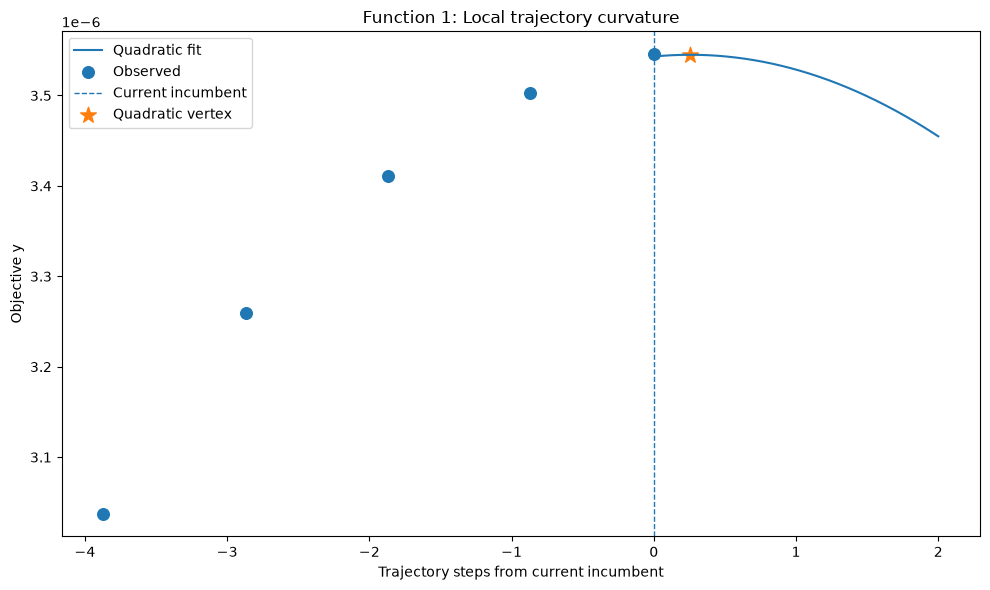

In [32]:
# LOCAL TRAJECTORY OPTIMISATION
# Fit a quadratic along the experimentally validated R6 → R7 → R9 → R10 → R11 trajectory.
# Read all observed coordinates and exact objective values from the active dataset.
# The fitted trajectory is a 1-D diagnostic, not proof of a 2-D optimum.

trajectory_data = df[df["Round"].isin(TRAJECTORY_ROUNDS)].sort_values("Round")
if len(trajectory_data) != len(TRAJECTORY_ROUNDS):
    missing = sorted(set(TRAJECTORY_ROUNDS) - set(trajectory_data["Round"]))
    raise ValueError(f"Missing trajectory rounds: {missing}")
if n_features != 2:
    raise ValueError("Trajectory analysis currently requires two input dimensions.")

X_trajectory = trajectory_data[feature_cols].to_numpy(dtype=np.float64)
y_trajectory = trajectory_data["y"].to_numpy(dtype=np.float64)
trajectory_anchor = incumbent_x.copy()
# Fit trajectory direction to observed coordinates (no fixed x1/x2 step).
# A signed principal component is scaled to the median positive projection
# between successive on-trajectory observations for interpretable t units.
trajectory_center = X_trajectory.mean(axis=0)
_, _, vh = np.linalg.svd(X_trajectory - trajectory_center, full_matrices=False)
trajectory_direction = vh[0]
if np.dot(trajectory_direction, X_trajectory[-1] - X_trajectory[0]) < 0:
    trajectory_direction *= -1
projected = (X_trajectory - trajectory_center) @ trajectory_direction
step_length = float(np.median(np.diff(projected)))
TRAJECTORY_STEP = trajectory_direction * step_length
print(f"Data-fitted trajectory step: {TRAJECTORY_STEP}")
# Project actual coordinates onto the established trajectory direction.
# R11 is slightly off the exact line due to six-decimal submission rounding.
t_obs = ((X_trajectory - trajectory_anchor) @ TRAJECTORY_STEP) / (TRAJECTORY_STEP @ TRAJECTORY_STEP)
if len(t_obs) < 4:
    raise ValueError("At least four trajectory observations are required for quadratic diagnostics.")

# Fit y(t) = a*t² + b*t + c; positive curvature implies no interior maximum.
a, b, c = np.polyfit(t_obs, y_trajectory, 2)
t_vertex = -b / (2.0 * a) if a < 0 else np.nan
x_vertex = trajectory_anchor + t_vertex * TRAJECTORY_STEP if np.isfinite(t_vertex) else np.full(2, np.nan)
y_vertex = np.polyval([a, b, c], t_vertex) if np.isfinite(t_vertex) else np.nan

t_grid = np.linspace(TRAJECTORY_T_MIN, TRAJECTORY_T_MAX, TRAJECTORY_GRID_POINTS)
X_grid = trajectory_anchor + t_grid[:, None] * TRAJECTORY_STEP
y_quad = np.polyval([a, b, c], t_grid)
gp_mean, gp_std = gp_local.predict(X_grid, return_std=True)
gp_best_idx = np.argmax(gp_mean)

comparison = pd.DataFrame([
    {"Candidate": "Current incumbent", "t": 0.0, "x1": trajectory_anchor[0], "x2": trajectory_anchor[1]},
    {"Candidate": "Quadratic vertex", "t": t_vertex, "x1": x_vertex[0], "x2": x_vertex[1]},
    {"Candidate": "Full next step", "t": 1.0, "x1": trajectory_anchor[0] + TRAJECTORY_STEP[0], "x2": trajectory_anchor[1] + TRAJECTORY_STEP[1]},
    {"Candidate": "GP trajectory mean maximum", "t": t_grid[gp_best_idx], "x1": X_grid[gp_best_idx, 0], "x2": X_grid[gp_best_idx, 1]}
])

print(f"FUNCTION {FUNCTION_ID}: LOCAL TRAJECTORY OPTIMISATION")
print("-" * 80)
print(f"Observed rounds: {trajectory_data['Round'].tolist()}")
print(f"Incumbent: ({trajectory_anchor[0]:.6f}, {trajectory_anchor[1]:.6f}) | y={incumbent_y:.16e}")
print(f"Quadratic: y(t) = {a:.6e} t² + {b:.6e} t + {c:.6e}")
print(f"Quadratic curvature a: {a:.6e}")
print(f"Quadratic vertex t:    {t_vertex:.6f}")
print(f"Quadratic vertex x:    ({x_vertex[0]:.6f}, {x_vertex[1]:.6f})")
print(f"Estimated vertex y:    {y_vertex:.6e}")
print("\nCANDIDATE COMPARISON")
display(comparison.style.format({"t": "{:.6f}", "x1": "{:.6f}", "x2": "{:.6f}"}))

plt.figure(figsize=(10, 6))
plt.plot(t_grid, y_quad, label="Quadratic fit")
plt.scatter(t_obs, y_trajectory, s=70, label="Observed")
plt.axvline(0, linestyle="--", linewidth=1, label="Current incumbent")
if np.isfinite(t_vertex):
    plt.scatter(t_vertex, y_vertex, marker="*", s=140, label="Quadratic vertex")
plt.xlabel("Trajectory steps from current incumbent")
plt.ylabel("Objective y")
plt.title(f"Function {FUNCTION_ID}: Local trajectory curvature")
plt.legend(); plt.tight_layout(); plt.show()


FUNCTION 1: LOCAL TRAJECTORY ROBUSTNESS
--------------------------------------------------------------------------------

EXTENDED GP TRAJECTORY
Search t range:          [0.0, 5.0]
GP maximum t:            0.095000
GP maximum x:            (0.671588, 0.700789)
GP transformed mean:     29.124667
GP transformed std:      0.002090
Maximum on boundary:     False

QUADRATIC VERTEX SENSITIVITY
Relative perturbation:   1.00%
Simulations:             10,000
Valid concave vertices:  62.28%
Median vertex t:         0.617687
95% vertex t interval:   [0.027069, 3.620521]
Median vertex x:         (0.671797, 0.700893)
95% vertex x range:      (0.671561, 0.700775) → (0.673000, 0.701491)

FINAL TRAJECTORY CANDIDATE COMPARISON


,Candidate,t,x1,x2
0,Current incumbent,0.000000,0.671550,0.700770
1,Full next step,1.000000,0.671950,0.700969
2,Quadratic vertex,0.256554,0.671653,0.700821
3,Robust quadratic median,0.617687,0.671797,0.700893
4,Extended GP mean maximum,0.095000,0.671588,0.700789


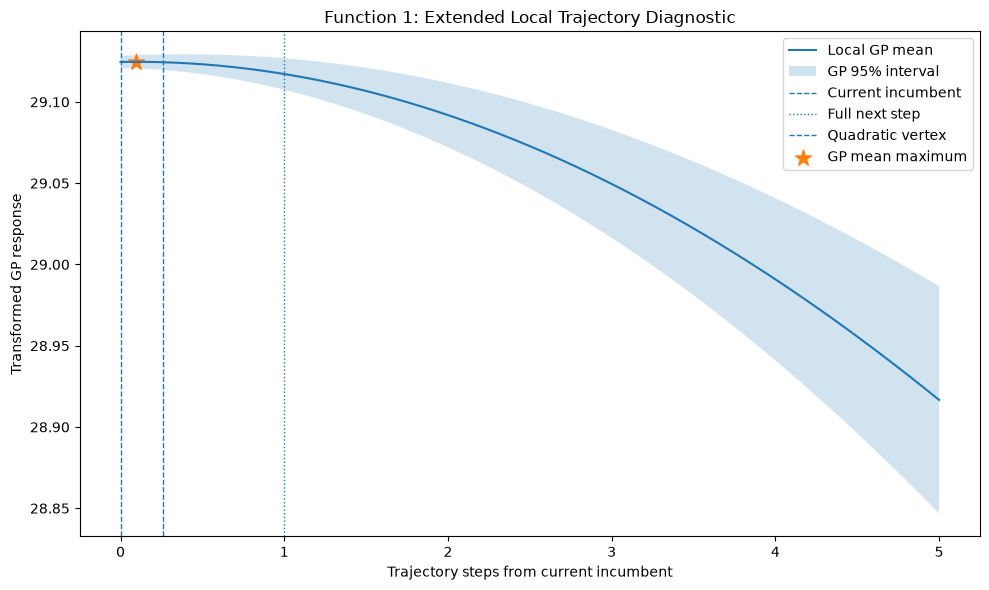

In [33]:
# LOCAL TRAJECTORY ROBUSTNESS DIAGNOSTIC
# Compare the GP mean along an extended trajectory with quadratic sensitivity.
# The perturbation experiment is a sensitivity analysis, NOT a calibrated confidence interval.

# Extended GP trajectory, always anchored at the current incumbent.
t_extended = np.linspace(EXTENDED_T_MIN, EXTENDED_T_MAX, EXTENDED_GRID_POINTS)
X_extended = trajectory_anchor + t_extended[:, None] * TRAJECTORY_STEP
gp_mean_ext, gp_std_ext = gp_local.predict(X_extended, return_std=True)
gp_best_idx = np.argmax(gp_mean_ext)
gp_best_t, gp_best_x = t_extended[gp_best_idx], X_extended[gp_best_idx]
gp_best_mean, gp_best_std = gp_mean_ext[gp_best_idx], gp_std_ext[gp_best_idx]
gp_at_boundary = gp_best_idx in (0, len(t_extended) - 1)

# Quadratic vertex sensitivity to hypothetical relative measurement perturbations.
rng = np.random.default_rng(QUADRATIC_RANDOM_SEED)
vertices_t = []
for _ in range(QUADRATIC_BOOTSTRAP_SAMPLES):
    y_sim = y_trajectory * (1.0 + rng.normal(0.0, QUADRATIC_RELATIVE_NOISE, size=len(y_trajectory)))
    a_sim, b_sim, _ = np.polyfit(t_obs, y_sim, 2)
    if a_sim < 0:
        t_sim = -b_sim / (2.0 * a_sim)
        if 0.0 <= t_sim <= VERTEX_T_MAX:
            vertices_t.append(t_sim)
vertices_t = np.asarray(vertices_t)
valid_fraction = len(vertices_t) / QUADRATIC_BOOTSTRAP_SAMPLES
vertex_t_median, vertex_t_low, vertex_t_high = (np.quantile(vertices_t, [0.5, 0.025, 0.975])
    if len(vertices_t) else (np.nan, np.nan, np.nan))
vertex_x_median = trajectory_anchor + vertex_t_median * TRAJECTORY_STEP
vertex_x_low = trajectory_anchor + vertex_t_low * TRAJECTORY_STEP
vertex_x_high = trajectory_anchor + vertex_t_high * TRAJECTORY_STEP

# All candidates derive from the current incumbent; no historical coordinates.
trajectory_comparison = pd.DataFrame([
    {"Candidate": "Current incumbent", "t": 0.0, "x1": trajectory_anchor[0], "x2": trajectory_anchor[1]},
    {"Candidate": "Full next step", "t": 1.0, "x1": trajectory_anchor[0] + TRAJECTORY_STEP[0], "x2": trajectory_anchor[1] + TRAJECTORY_STEP[1]},
    {"Candidate": "Quadratic vertex", "t": t_vertex, "x1": x_vertex[0], "x2": x_vertex[1]},
    {"Candidate": "Robust quadratic median", "t": vertex_t_median, "x1": vertex_x_median[0], "x2": vertex_x_median[1]},
    {"Candidate": "Extended GP mean maximum", "t": gp_best_t, "x1": gp_best_x[0], "x2": gp_best_x[1]}
])

print(f"FUNCTION {FUNCTION_ID}: LOCAL TRAJECTORY ROBUSTNESS")
print("-" * 80)
print("\nEXTENDED GP TRAJECTORY")
print(f"Search t range:          [{EXTENDED_T_MIN:.1f}, {EXTENDED_T_MAX:.1f}]")
print(f"GP maximum t:            {gp_best_t:.6f}")
print(f"GP maximum x:            ({gp_best_x[0]:.6f}, {gp_best_x[1]:.6f})")
print(f"GP transformed mean:     {gp_best_mean:.6f}")
print(f"GP transformed std:      {gp_best_std:.6f}")
print(f"Maximum on boundary:     {gp_at_boundary}")
print("\nQUADRATIC VERTEX SENSITIVITY")
print(f"Relative perturbation:   {QUADRATIC_RELATIVE_NOISE:.2%}")
print(f"Simulations:             {QUADRATIC_BOOTSTRAP_SAMPLES:,}")
print(f"Valid concave vertices:  {valid_fraction:.2%}")
print(f"Median vertex t:         {vertex_t_median:.6f}")
print(f"95% vertex t interval:   [{vertex_t_low:.6f}, {vertex_t_high:.6f}]")
print(f"Median vertex x:         ({vertex_x_median[0]:.6f}, {vertex_x_median[1]:.6f})")
print(f"95% vertex x range:      ({vertex_x_low[0]:.6f}, {vertex_x_low[1]:.6f}) → ({vertex_x_high[0]:.6f}, {vertex_x_high[1]:.6f})")
print("\nFINAL TRAJECTORY CANDIDATE COMPARISON")
display(trajectory_comparison.style.format({"t": "{:.6f}", "x1": "{:.6f}", "x2": "{:.6f}"}))

plt.figure(figsize=(10, 6))
plt.plot(t_extended, gp_mean_ext, label="Local GP mean")
plt.fill_between(t_extended, gp_mean_ext - 1.96 * gp_std_ext,
                 gp_mean_ext + 1.96 * gp_std_ext, alpha=0.2, label="GP 95% interval")
plt.axvline(0, linestyle="--", linewidth=1, label="Current incumbent")
plt.axvline(1, linestyle=":", linewidth=1, label="Full next step")
if np.isfinite(t_vertex):
    plt.axvline(t_vertex, linestyle="--", linewidth=1, label="Quadratic vertex")
plt.scatter(gp_best_t, gp_best_mean, marker="*", s=140, label="GP mean maximum")
plt.xlabel("Trajectory steps from current incumbent")
plt.ylabel("Transformed GP response")
plt.title(f"Function {FUNCTION_ID}: Extended Local Trajectory Diagnostic")
plt.legend(); plt.tight_layout(); plt.show()


In [34]:
# TWO-DIMENSIONAL LOCAL EXPLORATION (ADDITIONAL DIAGNOSTIC)
# The high-value observations almost lie on one line. This diagnostic compares
# GP predictions along the learned trajectory and its perpendicular direction.
# It is NOT a substitute for experimental evaluation; off-axis GP predictions
# may be unreliable because off-axis high-value observations are scarce.
# The diagnostic does not change the baseline acquisition or GP fit.
if n_features != 2: raise ValueError("This exploration diagnostic requires 2-D inputs")
perpendicular = np.array([-trajectory_direction[1], trajectory_direction[0]])
exploration_rows = []
for radius in EXPLORATION_RADII:
    for label, direction in [("Along +", trajectory_direction), ("Along -", -trajectory_direction),
                             ("Perpendicular +", perpendicular), ("Perpendicular -", -perpendicular),
                             ("x1 +", np.array([1., 0.])), ("x1 -", np.array([-1., 0.])),
                             ("x2 +", np.array([0., 1.])), ("x2 -", np.array([0., -1.]))]:
        point = np.clip(incumbent_x + radius * direction, 0., 1.)
        mean, std = gp_local.predict(point[None, :], return_std=True)
        exploration_rows.append({"Radius": radius, "Direction": label, "x1": point[0], "x2": point[1],
                                 "GP_Transformed_Mean": mean[0], "GP_Std": std[0],
                                 "Distance_to_Nearest_Observation": np.linalg.norm(X - point, axis=1).min()})
exploration_df = pd.DataFrame(exploration_rows)
print("LOCAL 2-D EXPLORATION: MODEL-BASED DIRECTIONAL COMPARISON")
display(exploration_df.style.format({"Radius":"{:.6f}","x1":"{:.6f}","x2":"{:.6f}",
                                    "GP_Transformed_Mean":"{:.6f}","GP_Std":"{:.6f}",
                                    "Distance_to_Nearest_Observation":"{:.6f}"}))


LOCAL 2-D EXPLORATION: MODEL-BASED DIRECTIONAL COMPARISON


,Radius,Direction,x1,x2,GP_Transformed_Mean,GP_Std,Distance_to_Nearest_Observation
0,0.000500,Along +,0.671998,0.700993,29.115105,0.005463,0.000500
1,0.000500,Along -,0.671102,0.700547,29.110804,0.002256,0.000111
2,0.000500,Perpendicular +,0.671327,0.701218,28.694364,0.319677,0.000500
3,0.000500,Perpendicular -,0.671773,0.700322,29.456156,0.323872,0.000500
4,0.000500,x1 +,0.672050,0.700770,29.296564,0.141399,0.000500
5,0.000500,x1 -,0.671050,0.700770,28.952577,0.141110,0.000227
6,0.000500,x2 +,0.671550,0.701270,28.724163,0.287682,0.000500
7,0.000500,x2 -,0.671550,0.700270,29.403145,0.290675,0.000481
8,0.001000,Along +,0.672445,0.701215,29.083413,0.011569,0.001000
9,0.001000,Along -,0.670655,0.700325,29.072756,0.002559,0.000164
